## Drainage Analysis

In [1]:
# Import necessary modules for the drainage area analysis
import geopandas as gpd
import rasterio
import rasterio.mask
import pystac_client
import planetary_computer
import stackstac
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
#Load Tokyo Prefecture shapefile and inspect the data
tokyo_shapefile = gpd.read_file('tokyo_prefecture_limits/N03-20260101_13.shp')
tokyo_shapefile.columns

Index(['N03_001', 'N03_002', 'N03_003', 'N03_004', 'N03_005', 'N03_007',
       'geometry'],
      dtype='object')

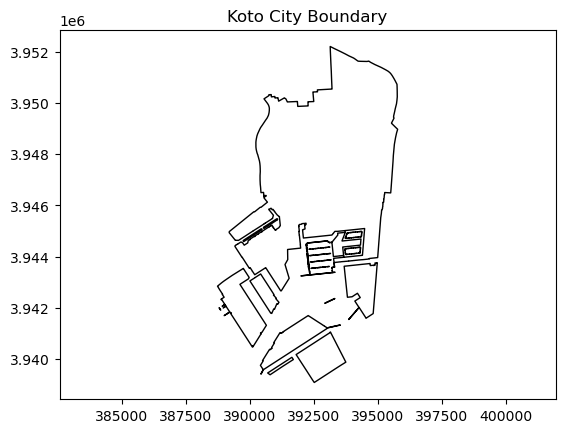

In [3]:
#Load koto city data and transform to crs
koto_city = tokyo_shapefile[(tokyo_shapefile["N03_004"] == "江東区") | (tokyo_shapefile['N03_007'] == '13108')].copy()
koto_city = koto_city.to_crs(epsg=32654)  # Transform to EPSG:32654 coordinate reference system
koto_city['area'] = koto_city.geometry.area / 1000000  # Calculate the area of the geometry in square kilometers

# print(koto_city[['N03_004', 'N03_007', 'area']])  # Display the relevant columns of the koto_city GeoDataFrame
koto_city.plot(edgecolor="black", facecolor="none")
plt.title("Koto City Boundary")
plt.axis("equal")
plt.show()

In [4]:
#Get the bounding box of Koto City in WGS84 coordinates
koto_wgs84 = koto_city.to_crs(epsg=4326)  # Transform to WGS84 coordinate reference system
koto_geometry = koto_wgs84.geometry.union_all()
koto_bbox = tuple(koto_wgs84.total_bounds)  # Get the bounding box of Koto City in WGS84 coordinates

In [5]:
#Connecting to the Planetary Computer STAC API and searching for Sentinel-2 imagery for Koto City
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

# Search for Sentinel-2 imagery within the bounding box of Koto City
search = catalog.search(collections=["sentinel-2-l2a"],bbox=koto_bbox, 
                        datetime="2020-01-01/2020-12-31", query={"eo:cloud_cover": {"lt": 15}})

items = search.item_collection()

In [6]:
#Signing assets for access to the Planetary Computer
signed_items = [planetary_computer.sign(item) for item in items]
#Loading spectral bands
bands = ["B02", "B03", "B04", "B08", "B11", "B12"]  # Blue, Green, Red, NIR bands, and SWIR bands

image_stack = stackstac.stack(signed_items, assets=bands, epsg=32654, resolution=10, 
                              bounds_latlon=koto_bbox)

In [7]:
koto_projected = koto_city.to_crs(epsg=32654)  # Transform Koto City geometry to match the image stack CRS  

In [8]:
#cloud filtered composite of the Sentinel-2 imagery for Koto City
composite = image_stack.median(dim="time", skipna=True).compute()

print(composite.shape)

(6, 1322, 712)


Text(0.5, 1.0, 'BSI')

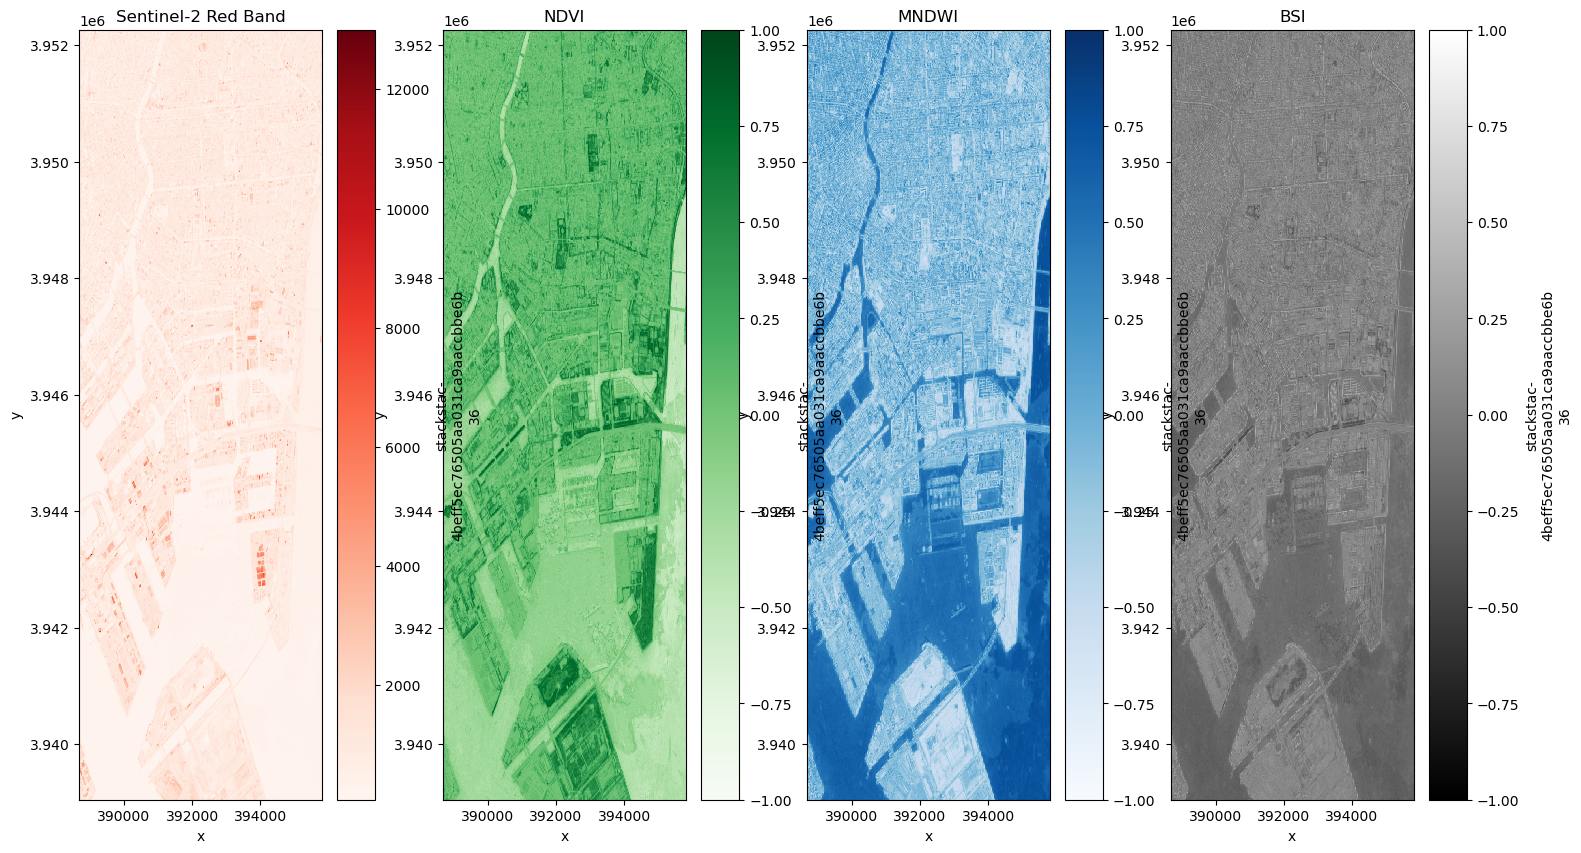

In [9]:
# Extracting bands and calculating land surface indices
blue = composite.sel(band="B02")
green = composite.sel(band="B03")
red = composite.sel(band="B04")
nir = composite.sel(band="B08")
swir1 = composite.sel(band="B11")
swir2 = composite.sel(band="B12")

ndvi = (nir - red) / (nir + red)
mndwi = (green - swir1) / (green + swir1)
ndbi = (swir1 - nir) / (swir1 + nir)
bsi = ((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue))
#plotting the calculated indices
fig, axes = plt.subplots(1, 4, figsize=(18, 10))

red.plot.imshow(ax=axes[0], cmap="Reds") # Plotting the Sentinel-2 Red Band showing the urban areas of Koto City
axes[0].set_title("Sentinel-2 Red Band")

ndvi.plot.imshow(ax=axes[1], cmap="Greens", vmin=-1, vmax=1)
axes[1].set_title("NDVI")

mndwi.plot.imshow(ax=axes[2], cmap="Blues", vmin=-1, vmax=1)
axes[2].set_title("MNDWI")

bsi.plot.imshow(ax=axes[3], cmap="gray", vmin=-1, vmax=1)
axes[3].set_title("BSI")

In [10]:
# Defining training data for land cover classification using Random Forest Classifier
from pyrosm import OSM

osm = OSM("koto.osm.pbf")  # Load the OSM data for Koto City

In [11]:
#Extracting building footprints and water bodies from OSM data
buildings = osm.get_buildings()
landuse = osm.get_landuse()
natural = osm.get_natural()
roads = osm.get_network(network_type="all")

#inspecting the extracted data fclass columns
print(f"Buildings columns: {buildings.columns}")
print(f"Landuse columns: {landuse.columns}")
print(f"Natural columns: {natural.columns}")
print(f"Roads columns: {roads.columns}")

Buildings columns: Index(['addr:city', 'addr:country', 'addr:housenumber', 'addr:housename',
       'addr:postcode', 'addr:place', 'addr:street', 'email', 'name',
       'opening_hours', 'operator', 'phone', 'ref', 'url', 'visible',
       'website', 'building', 'amenity', 'building:flats', 'building:levels',
       'building:material', 'building:min_level', 'building:use', 'craft',
       'height', 'internet_access', 'landuse', 'levels', 'office', 'shop',
       'source', 'start_date', 'wikipedia', 'id', 'timestamp', 'version',
       'tags', 'osm_type', 'geometry', 'changeset'],
      dtype='object')
Landuse columns: Index(['version', 'tags', 'lon', 'timestamp', 'lat', 'id', 'visible',
       'changeset', 'landuse', 'residential', 'geometry', 'osm_type',
       'construction', 'depot', 'industrial', 'port'],
      dtype='object')
Natural columns: Index(['version', 'tags', 'lon', 'timestamp', 'lat', 'id', 'visible',
       'changeset', 'natural', 'geometry', 'osm_type', 'water'],
    

In [12]:
#Assigning training labels based on OSM data for land cover classification
t_buildings = buildings.to_crs("EPSG:32654")[["geometry"]].copy()
t_buildings["class"] = "impervious"

t_vegetation = landuse.to_crs("EPSG:32654")
t_vegetation = t_vegetation[t_vegetation["landuse"].isin(["forest", "grass", "recreation_ground"])]
[["geometry"]].copy()
t_vegetation["class"] = "vegetation"

t_water = natural.to_crs("EPSG:32654")
t_water = t_water[t_water["water"].isin(["water", "river", "stream"])][["geometry"]].copy()
t_water["class"] = "water"

training_polygons = [t_buildings, t_vegetation, t_water]

In [13]:
# Convert roads to the projected CRS and buffer them into polygons, 
# clipping them to the Koto City boundary to create training polygons for the "impervious" class
koto_mask = koto_city.to_crs("EPSG:32654").geometry.union_all()

t_roads = roads.to_crs("EPSG:32654")

road_indices = t_roads.sindex.query(
    koto_mask,
    predicate="intersects"
)

t_roads = t_roads.iloc[road_indices].copy()
t_roads = gpd.clip(t_roads, koto_mask)

t_roads_polygons = t_roads[["geometry"]].copy()
t_roads_polygons["geometry"] = t_roads_polygons.geometry.buffer(3)
t_roads_polygons["class"] = "impervious"

# Soil classification for training data using OSM data, mostly construction sites, farmland, and other soil types. This will be used to train the Random Forest Classifier for land cover classification.
t_soil = landuse.to_crs("EPSG:32654")
t_soil = t_soil[t_soil["landuse"].isin(["construction", "farmland", "brownfield", "allotments"])]
t_soil = t_soil[["geometry"]].copy()
t_soil["class"] = "soil"

In [14]:
#Building a GeoDataFrame for training polygons by concatenating the individual class polygons
training_polygons = [t_buildings, t_vegetation, t_water, t_soil, t_roads_polygons]

training_polygons_gdf = gpd.GeoDataFrame(pd.concat(training_polygons, ignore_index=True), 
    geometry="geometry", crs="EPSG:32654")

In [15]:
# Sampling Sentinel-2 imagery for training data
# by extracting pixel values for each band and the calculated indices

feature_arrays = [blue.values, green.values, red.values, nir.values, swir1.values,
    swir2.values, ndvi.values, mndwi.values, ndbi.values, bsi.values]

image_features = np.stack(feature_arrays, axis=-1)
print(f"Image features shape: {image_features.shape}")

Image features shape: (1322, 712, 10)


In [16]:
from rasterio.features import geometry_mask
from affine import Affine

transform = Affine(float(composite.x[1] - composite.x[0]), 0, float(composite.x[0]),
    0, float(composite.y[1] - composite.y[0]), float(composite.y[0]))

training_features = []
training_labels = []

for _, sample in training_polygons_gdf.iterrows():
    mask = geometry_mask([sample.geometry],out_shape=image_features.shape[:2],
                        transform=transform, invert=True)

    pixels = image_features[mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    training_features.append(pixels)
    training_labels.extend([sample["class"]] * len(pixels))

training_features = np.vstack(training_features)
training_labels = np.asarray(training_labels)

In [17]:
from rasterio.features import geometry_mask
from rasterio.transform import from_origin

TARGET_CRS = "EPSG:32654"

koto_projected = koto_city.to_crs(TARGET_CRS)
koto_geometry = koto_projected.geometry.union_all()

n_rows, n_cols, n_features = image_features.shape

x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(np.median(np.diff(x_values))))
y_resolution = abs(float(np.median(np.diff(y_values))))

left = float(x_values.min()) - x_resolution / 2
top = float(y_values.max()) + y_resolution / 2

transform = from_origin(
    left,
    top,
    x_resolution,
    y_resolution
)

koto_pixel_mask = geometry_mask(
    [koto_geometry],
    out_shape=(n_rows, n_cols),
    transform=transform,
    invert=True
)

print(koto_pixel_mask.shape)
print(koto_pixel_mask.dtype)

(1322, 712)
bool


In [18]:
#Flattening the image features and using the Boolean mask to filter out pixels outside Koto City
#  for training the Random Forest Classifier
image_features = np.asarray(image_features, dtype=np.float32)
image_features_2d = image_features.reshape(-1, n_features)

inside_koto = koto_pixel_mask.reshape(-1)

valid_image_pixels = (
    inside_koto
    & np.isfinite(image_features_2d).all(axis=1)
)

In [19]:
#Training the Random Forest Classifier using the sampled training data
training_features = np.asarray(training_features, dtype=np.float32)
training_labels = np.asarray(training_labels)

valid_training = np.isfinite(training_features).all(axis=1)

classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

classifier.fit(
    training_features[valid_training],
    training_labels[valid_training]
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [20]:
classified_flat = np.full(
    image_features_2d.shape[0],
    -1,
    dtype=np.int8
)

class_names = np.unique(training_labels[valid_training])
class_to_code = {
    class_name: code
    for code, class_name in enumerate(class_names)
}

predicted_labels = classifier.predict(
    image_features_2d[valid_image_pixels]
)

classified_flat[valid_image_pixels] = np.array(
    [class_to_code[label] for label in predicted_labels],
    dtype=np.int8
)

classified = classified_flat.reshape(n_rows, n_cols)

print(classified.shape)
print(class_to_code)

(1322, 712)
{np.str_('impervious'): 0, np.str_('soil'): 1, np.str_('vegetation'): 2, np.str_('water'): 3}


In [21]:
# from sklearn.preprocessing import LabelEncoder

# # Ensure the feature arrays are numeric
# image_features = np.asarray(image_features, dtype=np.float32)
# training_features = np.asarray(training_features, dtype=np.float32)

# n_rows, n_cols, n_features = image_features.shape

# # Remove invalid training rows
# valid_training = np.isfinite(training_features).all(axis=1)

# training_features_clean = training_features[valid_training]
# training_labels_clean = np.asarray(training_labels)[valid_training]

# # Flatten image features for scikit-learn
# image_features_2d = image_features.reshape(-1, n_features)

# # Only classify valid pixels inside Koto City
# koto_pixels = koto_mask.reshape(-1)

# valid_image = (koto_pixels & np.isfinite(image_features_2d).all(axis=1))

# classifier = RandomForestClassifier(n_estimators=300, random_state=42, 
#             class_weight="balanced",n_jobs=-1)

# classifier.fit(training_features_clean, training_labels_clean)

# # Use -1 as a numeric value for pixels outside Koto or invalid pixels
# classified_flat = np.full(image_features_2d.shape[0], -1, dtype=np.int8)

# # Convert class names to numeric codes
# class_names = np.unique(training_labels_clean)
# class_to_code = {class_name: code for code, class_name in enumerate(class_names)}

# predicted_labels = classifier.predict(image_features_2d[valid_image])

# classified_flat[valid_image] = np.array(
# [class_to_code[label] for label in predicted_labels], dtype=np.int8)

# classified = classified_flat.reshape(n_rows, n_cols)

# print("Class codes:", class_to_code)
# print("Classified shape:", classified.shape)

In [22]:
#Determining resolution of the classified image and calculating the area of each class in square kilometers
x_res = abs(float(composite.x[1] - composite.x[0]))
y_res = abs(float(composite.y[1] - composite.y[0]))
pixel_area_m2 = x_res * y_res
pixel_area_km2 = pixel_area_m2 / 1e6
valid_classified = classified[classified >= 0]

class_counts = pd.Series(valid_classified).value_counts().sort_index()

area_table = pd.DataFrame({
    "class_code": class_counts.index,
    "pixel_count": class_counts.values
})

area_table["class"] = area_table["class_code"].map(
    {code: name for name, code in class_to_code.items()}
)

area_table["area_m2"] = (
    area_table["pixel_count"] * pixel_area_m2
)

area_table["area_km2"] = (
    area_table["area_m2"] / 1_000_000
)

area_table["fraction"] = (
    area_table["area_m2"] /
    area_table["area_m2"].sum()
)

print(area_table)

   class_code  pixel_count       class     area_m2  area_km2  fraction
0           0       344936  impervious  34493600.0   34.4936  0.780964
1           1         5744        soil    574400.0    0.5744  0.013005
2           2        54458  vegetation   5445800.0    5.4458  0.123297
3           3        36542       water   3654200.0    3.6542  0.082734


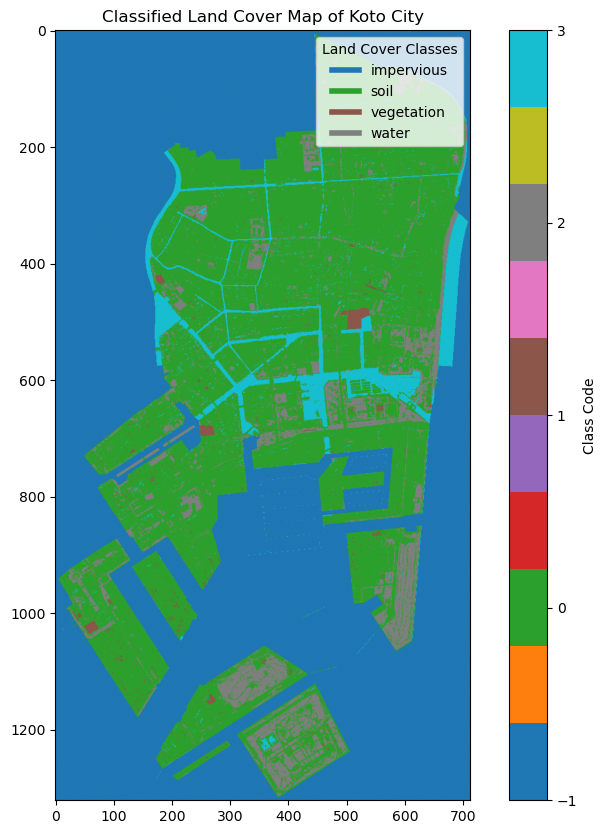

In [23]:
# Plotting the classified land cover map for Koto City
classes = list(class_to_code.keys())


plt.figure(figsize=(10, 10))
plt.imshow(classified, cmap="tab10", vmin=-1, vmax=len(class_to_code)-1)
plt.colorbar(ticks=np.arange(-1, len(class_to_code)), label="Class Code")
plt.title("Classified Land Cover Map of Koto City")
plt.legend(handles=[plt.Line2D([0], [0], color=plt.cm.tab10(i / len(class_to_code)), lw=4, label=cls) for i, cls in enumerate(classes)], title="Land Cover Classes")


In [24]:
transform = Affine(
    float(composite.x[1] - composite.x[0]),
    0,
    float(composite.x[0]),
    0,
    float(composite.y[1] - composite.y[0]),
    float(composite.y[0])
)

In [25]:
from rasterio.features import geometry_mask
from rasterio.transform import from_origin

x_values = composite.x.values
y_values = composite.y.values

x_resolution = abs(float(np.median(np.diff(x_values))))
y_resolution = abs(float(np.median(np.diff(y_values))))

left = float(x_values.min()) - x_resolution / 2
top = float(y_values.max()) + y_resolution / 2

transform = from_origin(
    left,
    top,
    x_resolution,
    y_resolution
)

training_features = []
training_labels = []

for _, sample in training_polygons_gdf.iterrows():
    sample_mask = geometry_mask(
        [sample.geometry],
        out_shape=image_features.shape[:2],
        transform=transform,
        invert=True
    )

    pixels = image_features[sample_mask]
    pixels = pixels[np.isfinite(pixels).all(axis=1)]

    if len(pixels) == 0:
        continue

    training_features.append(pixels)
    training_labels.extend(
        [sample["class"]] * len(pixels)
    )

training_features = np.vstack(training_features).astype(np.float32)
training_labels = np.asarray(training_labels)

print(pd.Series(training_labels).value_counts())

impervious    247275
water          61398
vegetation     14642
soil            5631
Name: count, dtype: int64


In [26]:
rng = np.random.default_rng(42)

labels = np.asarray(training_labels)
class_names = np.unique(labels)

samples_per_class = min(
    np.sum(labels == class_name)
    for class_name in class_names
)

selected_indices = []

for class_name in class_names:
    indices = np.where(labels == class_name)[0]
    selected_indices.extend(
        rng.choice(
            indices,
            size=samples_per_class,
            replace=False
        )
    )

selected_indices = np.asarray(selected_indices)

training_features_balanced = training_features[selected_indices]
training_labels_balanced = labels[selected_indices]

print(pd.Series(training_labels_balanced).value_counts())

impervious    5631
soil          5631
vegetation    5631
water         5631
Name: count, dtype: int64


In [27]:
classifier.fit(
    training_features_balanced,
    training_labels_balanced
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

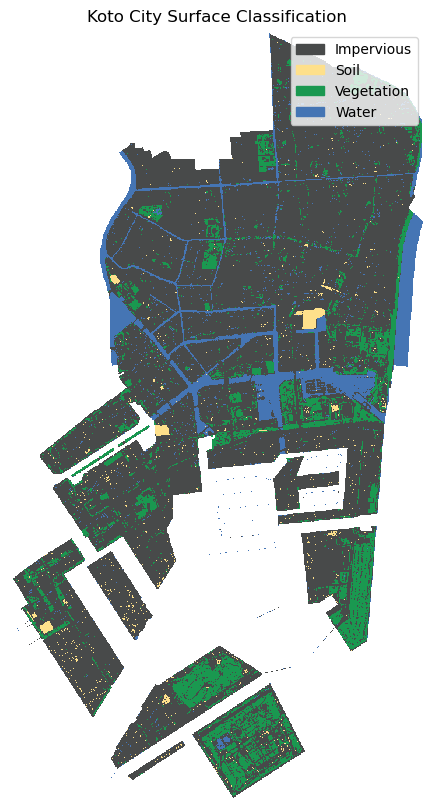

In [28]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

class_colors = {
    "impervious": "#484A4A",
    "vegetation": "#1a9850",
    "water": "#4575b4",
    "soil": "#fee08b"
}

display_array = classified.astype(float)
display_array[display_array < 0] = np.nan

colors = [
    class_colors[class_name]
    for class_name in class_names
]

plt.figure(figsize=(12, 10))
plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1,
    interpolation="nearest"
)

legend_handles = [
    Patch(
        color=class_colors[class_name],
        label=class_name.title()
    )
    for class_name in class_names
]

plt.legend(
    handles=legend_handles,
    loc="upper right"
)

plt.title("Koto City Surface Classification")
plt.axis("off")
plt.show()

In [29]:
valid_pixels = classified[classified >= 0]

predicted_counts = pd.Series(valid_pixels).value_counts()

predicted_table = pd.DataFrame({
    "class_code": predicted_counts.index,
    "pixel_count": predicted_counts.values
})

predicted_table["class"] = predicted_table["class_code"].map(
    {code: name for name, code in class_to_code.items()}
)

predicted_table["fraction"] = (
    predicted_table["pixel_count"]
    / predicted_table["pixel_count"].sum()
)

print(predicted_table)

   class_code  pixel_count       class  fraction
0           0       344936  impervious  0.780964
1           2        54458  vegetation  0.123297
2           3        36542       water  0.082734
3           1         5744        soil  0.013005


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

X = training_features_balanced
y = training_labels_balanced

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

classifier = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_val)

print(confusion_matrix(y_val, y_pred, labels=class_names))
print(classification_report(
    y_val,
    y_pred,
    labels=class_names,
    target_names=class_names,
    zero_division=0
))

[[ 745  211  124   46]
 [ 313  706   68   39]
 [  84   40  988   15]
 [  68   35    8 1015]]
              precision    recall  f1-score   support

  impervious       0.62      0.66      0.64      1126
        soil       0.71      0.63      0.67      1126
  vegetation       0.83      0.88      0.85      1127
       water       0.91      0.90      0.91      1126

    accuracy                           0.77      4505
   macro avg       0.77      0.77      0.77      4505
weighted avg       0.77      0.77      0.77      4505



# Water Balance Model

**Water balance modeling for Koto City using the classified land cover data & hydraulic inputs**

Using known inundation levels, estimates for infiltration rates, sewer drainage capacity,and with surface flow towards the nearest water body, we can estimate the potential inundation drainage duration for Koto City after a heavy rainfall event. 

Knowing point data of inundation depth and linearly interpolating between points we can determine the amount of flooded area. Then looking at the distance between the inundation point it can be classified as draining into a waterbody, the sewer or vegetation.

Needing estimates for slope & roughness.

GROUNDWATER ONLY REALLY COMES TO THE SURFACE IN THE FLOODPLAINS OF THE MAJOR RIVERS DURING THE 21-9 TYPHOON, MENTION THIS IN THE RESULTS/DISCUSSION AS A CONSIDERATION FOR THIS MODEL

In [45]:
#Loading shinsui kotonaibu data csv, and converting to projected CRS for analysis
inundation_data = gpd.read_file("shinsui_koutounaibu.csv", crs="EPSG:32654")
inundation_gdf = gpd.GeoDataFrame(inundation_data, geometry=gpd.points_from_xy(inundation_data['latitude'], inundation_data['longitude']), crs="EPSG:32654")

c:\Users\foozd\tudelft-conda\envs\mude-week-2-4\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: driver CSV does not support open option CRS
  return ogr_read(


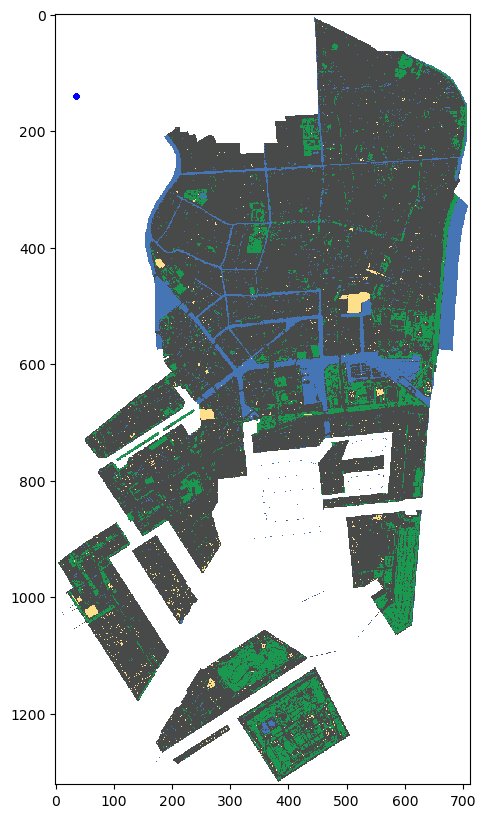

In [61]:
#Plotting the inundation depth data on top of the classified land cover map for Koto City


plt.figure(figsize=(12, 10))

plt.imshow(
    display_array,
    cmap=ListedColormap(colors),
    vmin=0,
    vmax=len(class_names) - 1,
    interpolation="nearest",
)
plt.scatter(inundation_gdf.geometry.x, inundation_gdf.geometry.y, 
            color='b', s=10, label='Inundation Depth Points', alpha=0.5)

In [ ]:
#Known/estimated parameters for the drainage areas in Koto City, including area, slope, and roughness coefficient. 

sewer_infiltration_maxcap = 50 #mm/hr any higher the sewer start to overflow.
slope = 1e-4 #Very gentle slope estimate, similar to Dutch river slopes.
rough_manning = 0.03 #Slighlty rougher concrete/asphalt, simulating street furniture.
vegetation_inf = 0.1 #Need to check realistic value
impervious_inf = 0.05 #Need to check realistic value



In [40]:
inundation_data.head() # Transform to EPSG:32654 coordinate reference system

,Map number,Flood depth,Ground height,latitude,longitude
0,1,0.4,-0.43,35.721375,139.8171875
1,1,0.37,-0.38,35.72154167,139.8173125
2,1,0.41,-0.45,35.72145834,139.8173125
3,1,0.42,-0.43,35.721375,139.8173125
4,1,0.37,-0.4,35.721625,139.8174375


In [ ]:
#Calculating flooded area and volume for each drainage area based on the inundation depth point data
#Using linear interpolation to estimate the inundation depth for each drainage area 

drainage_areas =

KeyError: 'drainage_area_km2'

In [33]:
# #Plot the different columns of the Tokyo Prefecture shapefile to visualize the data
# # tokyo_shapefile.plot(column='N03_001', legend=True, figsize=(10, 10))
# # tokyo_shapefile.plot(column='N03_002', legend=True, figsize=(10, 10))
# # tokyo_shapefile.plot(column='N03_003', legend=True, figsize=(10, 10))
# # tokyo_shapefile.plot(column='N03_004', legend=True, figsize=(10, 10))
# # tokyo_shapefile.plot(column='N03_005', legend=True, figsize=(10, 10))
# # tokyo_shapefile.plot(column='N03_007', legend=True, figsize=(10, 10))
# #Column 'N03_007' represents the administrative codes for the different municipalities within Tokyo Prefecture.

# plt.show()
# print(koto_bbox)



# # # Calculating the percentage of impervious surface area within Koto City
# # valid_area = ~np.isnan(classified)


# # impervious_fraction = ( np.sum((classified == "impervious") & valid_area)
# #     / np.sum(valid_area))
# # print(f"Impervious surface fraction in Koto City: {impervious_fraction:.4f} ({impervious_fraction*100:.2f}%)")

# # # Extracting impervious area, vegetation area, and water area from the classified image
# # impervious_area = (classified == "impervious").astype(np.uint8)
# # vegetation_area = (classified == "vegetation").astype(np.uint8)
# # water_area = (classified == "water").astype(np.uint8)
# # # Plotting the classified land cover map for Koto City
# # plt.figure(figsize=(12, 10))
# # plt.imshow(classified, cmap="tab10", interpolation="nearest")
# # plt.title("Classified Land Cover Map for Koto City")
# # plt.axis("off")
# # # Create a legend for the classified land cover map
# # from matplotlib.patches import Patch
# # legend_elements = [Patch(facecolor="tab:blue", label="Impervious"),
# #     Patch(facecolor="tab:green", label="Vegetation"), Patch(facecolor="tab:orange", label="Water")]
# # plt.legend(handles=legend_elements, loc="upper right")

# # Validating the classification using a confusion matrix and classification report
# # Splitting the training data into training and testing sets

# # X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# from rasterio.transform import from_bounds
# TARGET_CRS = "EPSG:32654"

# # 1. Prepare the Koto City mask
# koto_projected = koto_city.to_crs(TARGET_CRS)
# koto_geometry = koto_projected.geometry.union_all()

# # 2. Build the image feature cube: rows x columns x features
# feature_names = [
#     "blue", "green", "red", "nir", "swir1", "swir2",
#     "ndvi", "mndwi", "ndbi", "bsi"
# ]

# feature_arrays = [
#     blue.values, green.values, red.values, nir.values,
#     swir1.values, swir2.values, ndvi.values,
#     mndwi.values, ndbi.values, bsi.values
# ]

# image_features = np.stack(feature_arrays, axis=-1)

# n_rows, n_cols, n_features = image_features.shape
# print("Image feature shape:", image_features.shape)

# # 3. Create the raster transform from the image coordinates
# x_values = composite.x.values
# y_values = composite.y.values

# x_resolution = abs(float(x_values[1] - x_values[0]))
# y_resolution = abs(float(y_values[1] - y_values[0]))

# left = float(x_values.min()) - x_resolution / 2
# right = float(x_values.max()) + x_resolution / 2
# bottom = float(y_values.min()) - y_resolution / 2
# top = float(y_values.max()) + y_resolution / 2

# transform = from_bounds(
#     left, bottom, right, top, n_cols, n_rows
# )

# # 4. Mask pixels outside Koto City
# koto_mask = geometry_mask(
#     [koto_geometry],
#     out_shape=(n_rows, n_cols),
#     transform=transform,
#     invert=True
# )

# # 5. Flatten the image for Random Forest prediction
# image_features_2d = image_features.reshape(-1, n_features)
# koto_pixels = koto_mask.reshape(-1)

# valid_pixels = (
#     koto_pixels
#     & np.isfinite(image_features_2d).all(axis=1)
# )

# # 6. Train the classifier
# classifier = RandomForestClassifier(
#     n_estimators=300,
#     random_state=42,
#     class_weight="balanced",
#     n_jobs=-1
# )

# classifier.fit(training_features, training_labels)

# # 7. Classify only valid pixels
# classified_flat = np.full(
#     image_features_2d.shape[0],
#     None,
#     dtype=object
# )

# classified_flat[valid_pixels] = classifier.predict(
#     image_features_2d[valid_pixels]
# )

# classified = classified_flat.reshape(n_rows, n_cols)

# # 8. Plot the classification
# plt.figure(figsize=(10, 8))
# plt.imshow(classified, interpolation="nearest", cmap="tab10")
# plt.title("Koto City Land-Cover Classification")
# plt.axis("off")
# plt.show()
# from matplotlib.colors import ListedColormap
# from matplotlib.patches import Patch

# class_colors = {
#     "impervious": "#d73027",
#     "vegetation": "#1a9850",
#     "water": "#4575b4",
#     "soil": "#fee08b"
# }

# class_to_code = {
#     class_name: code
#     for code, class_name in enumerate(class_names)
# }

# display_array = np.full(classified.shape, np.nan)

# for class_name, code in class_to_code.items():
#     display_array[classified == code] = code

# colors = [
#     class_colors[class_name]
#     for class_name in class_names
# ]

# plt.figure(figsize=(10, 8))
# plt.imshow(
#     display_array,
#     cmap=ListedColormap(colors),
#     vmin=0,
#     vmax=len(class_names) - 1
# )

# legend_handles = [
#     Patch(color=class_colors[class_name], label=class_name.title())
#     for class_name in class_names
# ]

# plt.legend(handles=legend_handles, loc="upper right")
# plt.imshow(classified, cmap=ListedColormap(colors), vmin=0, vmax=len(class_names) - 1)
# plt.title("Koto City Surface Classification")
# plt.axis("off")
# plt.show()